# Facial Recognition

**Source:** https://labs.acme.byu.edu/Volume1/FacialRecognition/FacialRecognition.html

The **eigenfaces** method is principal component analysis applied to images. Stack one flattened photo per person as the columns of $F$ and subtract the mean face. The leading left singular vectors of the result form an orthonormal basis of "eigenfaces". Projecting faces onto the first $s$ eigenfaces compresses each $36{,}000$-pixel image to $s$ numbers, and recognition becomes a nearest-neighbor search in that small space.

In [1]:
import os, io, zipfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from imageio.v3 import imread
from scipy import linalg as la

# faces94.zip (about 18 MB) is downloaded on demand and is not committed.
DATA = "data"
FACES = os.path.join(DATA, "faces94.zip")
DATA_ZIP = "https://labs.acme.byu.edu/_downloads/cd57fdc58cb148989317c4f539afff55/FacialRecognition.zip"
os.makedirs(DATA, exist_ok=True)
if not os.path.exists(FACES):
    with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(DATA_ZIP).read())) as z:
        with open(FACES, "wb") as fh:
            fh.write(z.read("faces94.zip"))
print(FACES, f"{os.path.getsize(FACES) / 1e6:.1f} MB")

data/faces94.zip 18.9 MB


## Preparing an Image Database

The lab's helper `get_faces()` takes the first image from each person's folder, converts it to grayscale, flattens it, and stacks the images as columns of $F$.

In [2]:
def get_faces(path=FACES):
    '''
    Traverse the specified directory (or zip file) to obtain one image from each subfolder,
    convert each image to grayscale, flatten it, and stack them as columns
    of a data matrix.

    Parameters
    ----------
    path : str
        Directory path (or zip archive) containing the faces94 dataset.

    Returns
    -------
    F : ndarray
        Each column of F is a vectorized face image (flattened to 1D).
    '''
    faces = []        # List to store flattened face images.
    subs = set()      # Track which subfolders have been sampled.

    # Open the zip file containing the dataset.
    with zipfile.ZipFile(path, 'r') as z:
        for info in z.infolist():
            # Skip directories (only process files).
            if info.is_dir():
                continue

            # Only take the *first* image from each subdirectory.
            dn = os.path.dirname(info.filename)
            if dn in subs:
                continue

            # Only process jpg images.
            if not info.filename.lower().endswith("jpg"):
                continue

            subs.add(dn)

            # Read the image from the archive, convert to grayscale, flatten.
            face = imread(z.read(info.filename)).mean(axis=2).ravel()
            faces.append(face)

    # Stack face vectors as columns in matrix F.
    return np.transpose(faces)

---

## Problem 1: Displaying a Flattened Face

F shape: (36000, 153)


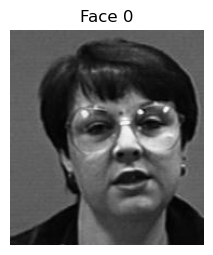

In [3]:
def show(image, m=200, n=180, ax=None, title=None):
    """Plot the flattened grayscale 'image' of width 'w' and height 'h'.

    Parameters:
        image ((mn,) ndarray): A flattened image.
        m (int): The original number of rows in the image.
        n (int): The original number of columns in the image.
    """
    ax = ax or plt.gca()
    ax.imshow(np.reshape(image, (m, n)), cmap="gray")
    ax.axis("off")
    if title:
        ax.set_title(title)


F = get_faces()
print("F shape:", F.shape)
plt.figure(figsize=(2.5, 3))
show(F[:, 0], title="Face 0")
plt.show()

## The Eigenfaces Method

Shifting by the mean face $\boldsymbol\mu = \frac1k\sum_i \mathbf{f}_i$ removes what all faces share and leaves what makes each one distinct: $\bar{\mathbf{f}}_i = \mathbf{f}_i - \boldsymbol\mu$, collected as the columns of $\bar F$.

Let $\bar F = U\Sigma V^T$ be the compact SVD. By Eckart-Young, the first $s$ columns of $U$ (the **eigenfaces**, which are eigenvectors of $\bar F\bar F^T$) span the best $s$-dimensional subspace for approximating $\bar F$. The coordinates of a face in that basis are

$$\widehat{\mathbf{f}}_i = U_s^T\bar{\mathbf{f}}_i, \qquad \widehat F = U_s^T\bar F,$$

and the reconstruction from those coordinates is $\widetilde{\mathbf{f}}_i = U_s\widehat{\mathbf{f}}_i + \boldsymbol\mu$.

---

## Problems 2, 3, and 5: The `FacialRec` Class

- **Problem 2:** The constructor builds $F$, the mean face $\boldsymbol\mu$, and the shifted faces $\bar F$.
- **Problem 3:** It also stores $U$ from the compact SVD of $\bar F$. `project()` computes $U_s^T A$ in one line.
- **Problem 5:** `find_nearest()` projects the database and the query, then returns $\arg\min_i \|\widehat{\mathbf{f}}_i - \widehat{\mathbf{g}}\|_2$.
- **Problem 6:** `match()` displays a query face beside its best match.

In [4]:
class FacialRec(object):
    """Class for storing a database of face images, with methods for
    matching other faces to the database.

    Attributes:
        F ((mn,k) ndarray): The flatten images of the dataset, where
            k is the number of people, and each original image is mxn.
        mu ((mn,) ndarray): The mean of all flatten images.
        Fbar ((mn,k) ndarray): The images shifted by the mean.
        U ((mn,k) ndarray): The U in the compact SVD of Fbar;
            the columns are the eigenfaces.
    """
    # Problems 2-3
    def __init__(self, path=FACES):
        """Initialize the F, mu, Fbar, and U attributes.
        This is the main part of the computation.
        """
        self.F = get_faces(path)
        self.mu = self.F.mean(axis=1)
        self.Fbar = self.F - self.mu[:, None]
        self.U, self.sigma, _ = la.svd(self.Fbar, full_matrices=False)

    # Problem 3
    def project(self, A, s):
        """Project a face vector onto the subspace spanned by the first s
        eigenfaces, and represent that projection in terms of those eigenfaces.

        Parameters:
            A((mn,) or (mn,l) ndarray): The array to be projected.
            s(int): the number of eigenfaces.
        Returns:
            ((s,) ndarray): An array of the projected image of s eigenfaces.
        """
        return self.U[:, :s].T @ A

    # Problem 5
    def find_nearest(self, g, s=38):
        """Find the index j such that the jth column of F is the face that is
        closest to the face image 'g'.

        Parameters:
            g ((mn,) ndarray): A flattened face image.
            s (int): the number of eigenfaces to use in the projection.

        Returns:
            (int): the index of the column of F that is the best match to
                   the input face image 'g'.
        """
        F_hat = self.project(self.Fbar, s)
        g_hat = self.project(g - self.mu, s)
        return int(np.argmin(la.norm(F_hat - g_hat[:, None], axis=0)))

    # Problem 6
    def match(self, image, s=38, m=200, n=180):
        """Display an image along with its closest match from the dataset.

        Parameters:
            image ((mn,) ndarray): A flattened face image.
            s (int): The number of eigenfaces to use in the projection.
            m (int): The original number of rows in the image.
            n (int): The original number of columns in the image.
        """
        j = self.find_nearest(image, s)
        fig, ax = plt.subplots(1, 2, figsize=(4.5, 3))
        show(image, m, n, ax[0], "Input")
        show(self.F[:, j], m, n, ax[1], f"Match (face {j})")
        plt.tight_layout()
        plt.show()
        return j


fr = FacialRec()
print("F:", fr.F.shape, " mu:", fr.mu.shape, " Fbar:", fr.Fbar.shape, " U:", fr.U.shape)
print("rank(Fbar) =", np.linalg.matrix_rank(fr.Fbar))

F: (36000, 153)  mu: (36000,)  Fbar: (36000, 153)  U: (36000, 153)
rank(Fbar) = 151


Subtracting the mean makes the columns of $\bar F$ sum to zero, so its rank is at most $k-1 = 152$. It is 151 because the dataset contains a duplicate: the first photos of two different people are identical.

faces 0 and 9: max pixel difference = 0.0


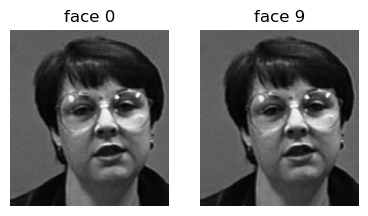

In [5]:
G_ = fr.F.T @ fr.F
sq = np.diag(G_)
d2 = sq[:, None] + sq[None, :] - 2 * G_
np.fill_diagonal(d2, np.inf)
i0, j0 = np.unravel_index(np.argmin(d2), d2.shape)
print(f"faces {i0} and {j0}: max pixel difference = {np.abs(fr.F[:, i0] - fr.F[:, j0]).max()}")
fig, ax = plt.subplots(1, 2, figsize=(4.5, 3))
show(fr.F[:, i0], ax=ax[0], title=f"face {i0}")
show(fr.F[:, j0], ax=ax[1], title=f"face {j0}")
plt.show()

### Problem 2 check: mean face, an original face, and its mean-shifted version (Figs. 1-3)

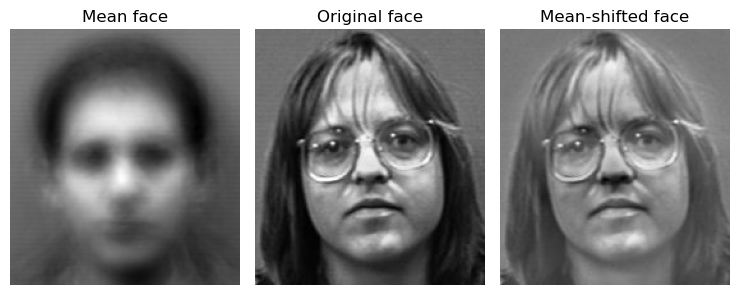

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(7.5, 3.2))
show(fr.mu, ax=ax[0], title="Mean face")
show(fr.F[:, 10], ax=ax[1], title="Original face")
show(fr.Fbar[:, 10], ax=ax[2], title="Mean-shifted face")
plt.tight_layout(); plt.show()

### Problem 3 check: eigenfaces (Fig. 4)

The first eigenface captures broad lighting and shape. Later ones carry finer, more person-specific detail.

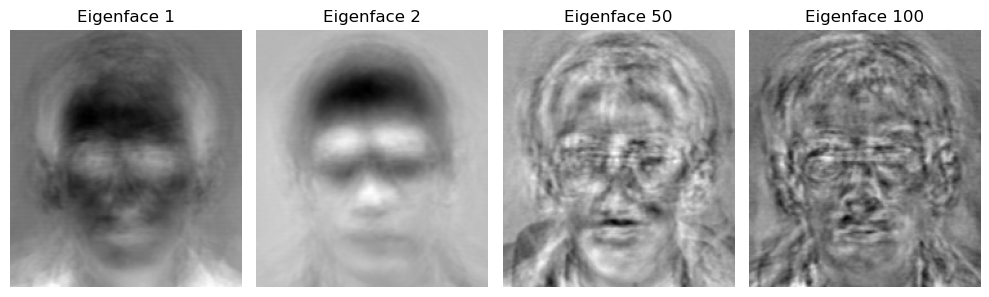

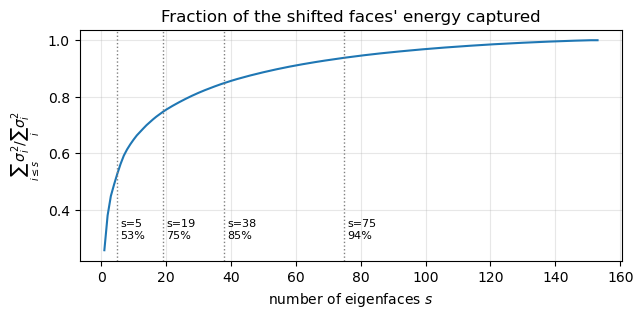

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(10, 3.2))
for a, i in zip(ax, [0, 1, 49, 99]):
    show(fr.U[:, i], ax=a, title=f"Eigenface {i + 1}")
plt.tight_layout(); plt.show()

energy = np.cumsum(fr.sigma**2) / np.sum(fr.sigma**2)
plt.figure(figsize=(7, 3))
plt.plot(np.arange(1, len(energy) + 1), energy)
for s in [5, 19, 38, 75]:
    plt.axvline(s, color="gray", ls=":", lw=1)
    plt.text(s + 1, 0.3, f"s={s}\n{energy[s-1]:.0%}", fontsize=8)
plt.xlabel("number of eigenfaces $s$")
plt.ylabel(r"$\sum_{i\leq s}\sigma_i^2 / \sum_i \sigma_i^2$")
plt.title("Fraction of the shifted faces' energy captured")
plt.grid(alpha=0.3); plt.show()

`project()` handles a single vector or a matrix of column vectors:

In [8]:
print("project(vector, 38):", fr.project(fr.Fbar[:, 0], 38).shape)
print("project(matrix, 38):", fr.project(fr.Fbar, 38).shape)

project(vector, 38): (38,)
project(matrix, 38): (38, 153)


---

## Problem 4: Reconstructions

Reconstruct one face with $\widetilde{\mathbf f}_i = U_s\widehat{\mathbf f}_i + \boldsymbol\mu$ for several values of $s$ (cf. Fig. 5).

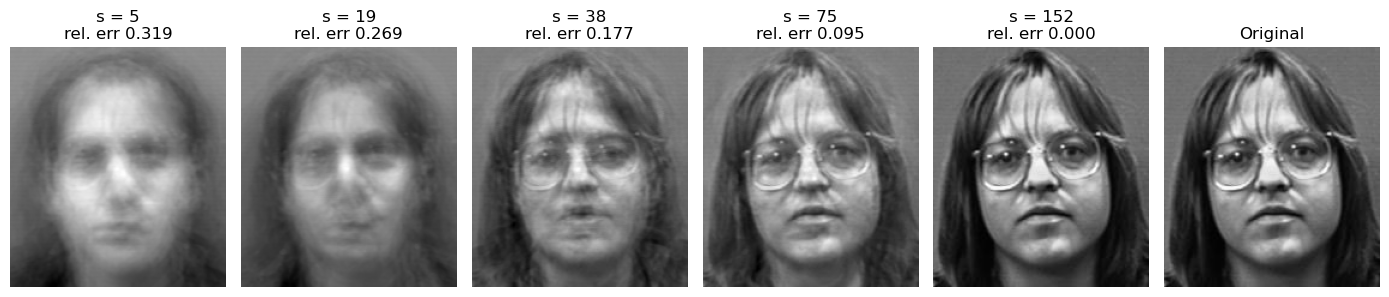

In [9]:
i = 10
ss = [5, 19, 38, 75, 152]
fig, ax = plt.subplots(1, len(ss) + 1, figsize=(14, 3.2))
for a, s in zip(ax, ss):
    f_hat = fr.project(fr.Fbar[:, i], s)
    f_tilde = fr.U[:, :s] @ f_hat + fr.mu
    rel = la.norm(f_tilde - fr.F[:, i]) / la.norm(fr.F[:, i])
    show(f_tilde, ax=a, title=f"s = {s}\nrel. err {rel:.3f}")
show(fr.F[:, i], ax=ax[-1], title="Original")
plt.tight_layout(); plt.show()

At $s=152$ the reconstruction is exact. $\bar F$ has rank 151, so every shifted face lies in the span of the first 151 eigenfaces.

---

## Problem 6: Matching Random Faces

The lab's `sample_faces()` generator yields random images from the whole dataset (about 20 photos per person), most of which are *not* the database image. It is used here with a fixed seed so the run is reproducible.

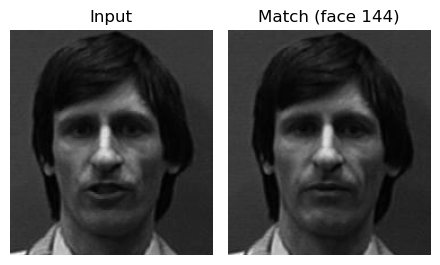

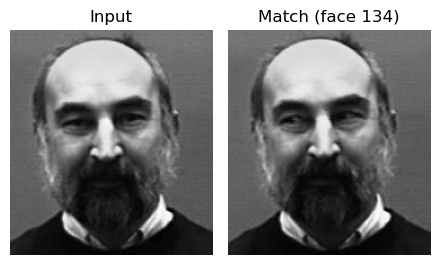

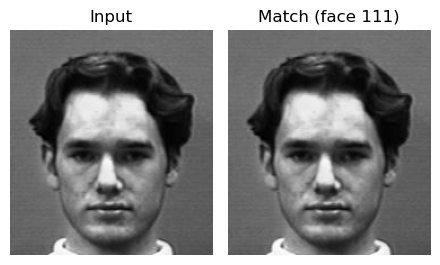

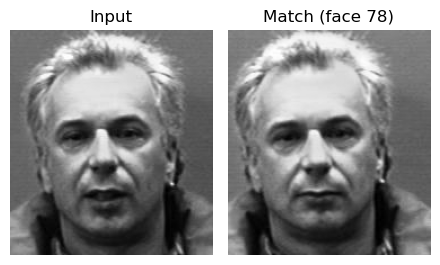

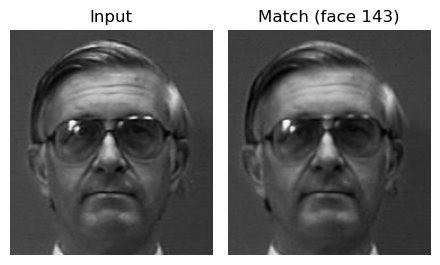

In [10]:
def sample_faces(k, path=FACES, seed=None):
    """Generate k sample images from the given path.

    Parameters
    ----------
    n (int):
        The number of sample images to obtain.
    path(str):
        The directory containing the dataset of images.

    Yields
    ------
    ((mn,) ndarray):
        An flattend mn-array representing a single
        image. k images are yielded in total.
    """
    files = [] # List to store possible files.

    # Open the zip file containing the dataset.
    with zipfile.ZipFile(path) as z:
        for info in z.infolist():

            # Only process jpg images.
            if not info.filename.lower().endswith("jpg"):
                continue

            # Store files to be sampled.
            files.append(info.filename)

        # Choose k files.
        rng = np.random.default_rng(seed)
        test_files = rng.choice(files, k, replace=False)

        # Read and yield the images.
        for fname in test_files:
            yield imread(z.read(fname)).mean(axis=2).ravel()


for test_image in sample_faces(5, seed=4):
    fr.match(test_image, s=38)

### Measuring accuracy

The lab says to expect over 90% accuracy. To measure it, each sampled file needs a label: the person folder it came from. The folder order below matches the column order of $F$, since both walk the zip in the same order. The database images themselves are excluded, so every test is a photo the system has never seen.

s =   1: accuracy 22.8%
s =   2: accuracy 55.2%
s =   3: accuracy 76.4%
s =   5: accuracy 78.8%
s =   8: accuracy 87.0%
s =  12: accuracy 90.6%
s =  19: accuracy 92.0%
s =  25: accuracy 92.8%
s =  38: accuracy 93.0%
s =  50: accuracy 92.6%
s =  75: accuracy 92.0%
s = 100: accuracy 91.8%
s = 152: accuracy 92.0%
raw pixels: accuracy 92.0%


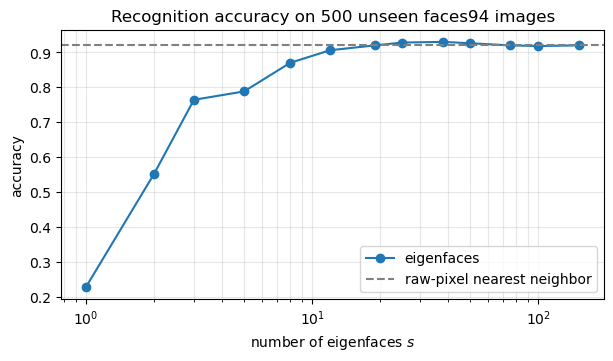

In [11]:
def labeled_samples(k, path=FACES, seed=0):
    """Yield (image, person_index) for k random non-database images."""
    with zipfile.ZipFile(path) as z:
        jpgs = [i.filename for i in z.infolist()
                if not i.is_dir() and i.filename.lower().endswith("jpg")]
        people, first = {}, set()
        for f in jpgs:
            d = os.path.dirname(f)
            if d not in people:
                people[d] = len(people)
                first.add(f)
        candidates = [f for f in jpgs if f not in first]
        rng = np.random.default_rng(seed)
        for f in rng.choice(candidates, k, replace=False):
            yield imread(z.read(f)).mean(axis=2).ravel(), people[os.path.dirname(f)]

tests = list(labeled_samples(500, seed=0))
G = np.column_stack([g for g, _ in tests])
labels = np.array([lab for _, lab in tests])

def accuracy(s):
    F_hat = fr.project(fr.Fbar, s)
    G_hat = fr.project(G - fr.mu[:, None], s)
    # Pairwise distances, shape (k, n_tests)
    d = la.norm(F_hat[:, :, None] - G_hat[:, None, :], axis=0)
    return np.mean(np.argmin(d, axis=0) == labels)

# The same check without any projection: nearest neighbor on raw pixels.
# Broadcasting F - g over all pairs would need 36000 x 153 x 500 floats (22 GB),
# so use ||f - g||^2 = ||f||^2 - 2 f.g + ||g||^2 (the ||g||^2 term doesn't change the argmin).
d2 = (fr.F**2).sum(axis=0)[:, None] - 2 * fr.F.T @ G
raw = np.mean(np.argmin(d2, axis=0) == labels)

s_values = [1, 2, 3, 5, 8, 12, 19, 25, 38, 50, 75, 100, 152]
accs = [accuracy(s) for s in s_values]
for s, a in zip(s_values, accs):
    print(f"s = {s:3d}: accuracy {a:.1%}")
print(f"raw pixels: accuracy {raw:.1%}")

plt.figure(figsize=(7, 3.5))
plt.semilogx(s_values, accs, "o-", label="eigenfaces")
plt.axhline(raw, color="gray", ls="--", label="raw-pixel nearest neighbor")
plt.xlabel("number of eigenfaces $s$"); plt.ylabel("accuracy")
plt.title("Recognition accuracy on 500 unseen faces94 images")
plt.legend(); plt.grid(alpha=0.3, which="both"); plt.show()

## Additional Material: A $k$-d Tree and $k$-Neighbors Voting

The lab suggests caching $\widehat F$ in a `scipy.spatial.KDTree` and turning the system into a $k$-neighbors classifier that uses several photos per person. Below, the database holds 5 photos per person, the test set is disjoint from it, and the $k$ nearest neighbors vote.

In [12]:
from scipy.spatial import KDTree
from collections import Counter

def build_multi_db(per_person=5, path=FACES):
    """Return (F, labels, used) with up to per_person images per person."""
    with zipfile.ZipFile(path) as z:
        jpgs = [i.filename for i in z.infolist()
                if not i.is_dir() and i.filename.lower().endswith("jpg")]
        people, count, cols, labs, used = {}, Counter(), [], [], set()
        for f in jpgs:
            d = os.path.dirname(f)
            people.setdefault(d, len(people))
            if count[d] < per_person:
                count[d] += 1
                cols.append(imread(z.read(f)).mean(axis=2).ravel())
                labs.append(people[d])
                used.add(f)
    return np.column_stack(cols), np.array(labs), used, people, jpgs

F5, lab5, used5, people, jpgs = build_multi_db(5)
mu5 = F5.mean(axis=1)
U5 = la.svd(F5 - mu5[:, None], full_matrices=False)[0]

rng = np.random.default_rng(1)
with zipfile.ZipFile(FACES) as z:
    test_files = rng.choice([f for f in jpgs if f not in used5], 500, replace=False)
    G5 = np.column_stack([imread(z.read(f)).mean(axis=2).ravel() for f in test_files])
y5 = np.array([people[os.path.dirname(f)] for f in test_files])

s = 38
tree = KDTree((U5[:, :s].T @ (F5 - mu5[:, None])).T)
Q = (U5[:, :s].T @ (G5 - mu5[:, None])).T
print(f"database: {F5.shape[1]} images of {len(people)} people; s = {s}")
for k in [1, 3, 5]:
    _, idx = tree.query(Q, k=k)
    idx = idx.reshape(len(Q), k)
    pred = np.array([Counter(lab5[row]).most_common(1)[0][0] for row in idx])
    print(f"k = {k}: accuracy {np.mean(pred == y5):.1%}")

database: 765 images of 153 people; s = 38
k = 1: accuracy 99.0%
k = 3: accuracy 98.2%
k = 5: accuracy 98.0%


## Discussion

- With one photo per person, eigenfaces at $s=38$ scored 93.0% on 500 unseen images, slightly better than nearest neighbor on all $36{,}000$ raw pixels (92.0%), while comparing only 38 numbers per face.
- Accuracy climbs quickly up to $s\approx 12$ and is flat or slightly lower beyond $s\approx 38$. The extra eigenfaces add detail that doesn't help tell these people apart.
- Using 5 photos per person in the database raised accuracy to 99.0% (with $k=1$). Choosing $s$ well mattered much less than that.
- The duplicated photo means two "people" share a database image, so with one photo per person any test image of either of them can be matched to the wrong label.